# Bank Telemarketing Success Prediction — ML Lab Implementations
**Dataset:** UCI Bank Marketing, `bank-full.csv` (45,211 calls, 17 columns), Moro, Cortez & Rita (2014).
**Task:** predict whether a client subscribes to a term deposit (`y = yes`) **before** the call is made.

| Section | Lab assignment | What is done here |
|---|---|---|
| 1 | Lab 1 — Cleaning & EDA | missing values, outliers, encoding, distributions, correlation, feature selection, PCA |
| 2 | Lab 3 — Regularization | no penalty vs L1 / L2 / ElasticNet logistic regression |
| 3 | Lab 4 — Classification & evaluation | 2014 baselines vs Random Forest, LightGBM, XGBoost, CatBoost and ensembles; imbalance handling; Optuna tuning |
| 4 | Lab 5 — RFM + K-Means | recency / frequency / monetary features, elbow & silhouette, cluster strategies |
| 5 | Lab 7 — Genetic Algorithm feature selection | GA over feature groups vs all / L1 / mutual-information subsets |
| 6 | Explainability | TreeSHAP values of the final model |

Labs 2 (house-price regression) and 6 (traffic-light RL) need different data/environments and are not applicable to this dataset.

In [1]:
import json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, precision_recall_curve,
                             brier_score_loss, silhouette_score, matthews_corrcoef,
                             accuracy_score, balanced_accuracy_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import lightgbm as lgb

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
FIG, RES = "figures/", "results/"
import os; os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)
RESULTS = {}
def save(name): plt.tight_layout(); plt.savefig(FIG + name, bbox_inches="tight"); plt.show()

# 1. Lab 1 — Data cleaning and exploratory data analysis

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")
print(df.shape); display(df.head())
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
print(df["y"].value_counts(normalize=True).round(4))
RESULTS["dataset"] = {"rows": len(df), "cols": df.shape[1],
                      "positive_rate": float((df.y == "yes").mean()),
                      "imbalance_ratio": float((df.y == "no").sum() / (df.y == "yes").sum())}
# Fix the 80/20 split now, so every learned statistic (caps, checks) can use training rows only.
IDX_TR, IDX_TE = train_test_split(df.index, test_size=.2, stratify=df.y, random_state=SEED)
print("train rows:", len(IDX_TR), "| test rows:", len(IDX_TE))

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Duplicate rows: 0
y
no     0.883
yes    0.117
Name: proportion, dtype: float64
train rows: 36168 | test rows: 9043


## 1.1 Missing values
The file has no empty cells, but missingness is hidden in **sentinels**: the string `unknown` and `pdays = -1` (never contacted).

In [3]:
print("Literal NaNs:", int(df.isna().sum().sum()))
cat_cols = [c for c in df.columns if df[c].dtype == object and c != "y"]
num_cols = [c for c in df.columns if df[c].dtype != object]
unk = pd.DataFrame({
    "unknown_count": [(df[c] == "unknown").sum() for c in cat_cols],
    "unknown_pct": [(df[c] == "unknown").mean() * 100 for c in cat_cols],
    "conv_rate_if_unknown": [(df.loc[df[c] == "unknown", "y"] == "yes").mean() * 100 for c in cat_cols],
    "conv_rate_if_known": [(df.loc[df[c] != "unknown", "y"] == "yes").mean() * 100 for c in cat_cols]},
    index=cat_cols).query("unknown_count > 0").round(2)
display(unk)
print("pdays == -1 (never contacted):", (df.pdays == -1).sum(), f"({(df.pdays==-1).mean()*100:.1f}%)")
RESULTS["unknown"] = unk.to_dict()

Literal NaNs: 0


,unknown_count,unknown_pct,conv_rate_if_unknown,conv_rate_if_known


pdays == -1 (never contacted): 36954 (81.7%)


**Treatment decision.** `unknown` converts at a very different rate from known values (e.g. `contact = unknown` ≈ 4% vs ≈ 15%), so it is **not missing at random**. Imputing it with the mode would destroy that signal.
* `unknown` is kept as its own category, and an explicit indicator (`unk_job`, `unk_education`, `unk_contact`, `unk_poutcome`) is added.
* `pdays = -1` is recoded to `NaN` with a `never_contacted` flag, because keeping -1 would tell a model "contacted yesterday".
* `duration` (call length) is **removed** from the predictive feature set. It is only known *after* the call, so it cannot be used to decide whom to call (data leakage). It is kept aside only to measure the leakage.

In [4]:
# Mode imputation vs keeping 'unknown' — quick check with the same simple model (training rows only)
def quick_auc(frame):
    X = pd.get_dummies(frame.drop(columns=["y", "duration"]), drop_first=True).astype(float)
    return cross_val_score(Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=2000))]), X,
                           (frame.y == "yes").astype(int), cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").mean()
imp = df.loc[IDX_TR].copy()
for c in ["job", "education", "contact", "poutcome"]:
    imp[c] = imp[c].replace("unknown", imp.loc[imp[c] != "unknown", c].mode()[0])
mv = {"keep_unknown_as_category": quick_auc(df.loc[IDX_TR]), "mode_imputation": quick_auc(imp)}
print({k: round(v, 4) for k, v in mv.items()}); RESULTS["missing_value_treatment_auc"] = mv

{'keep_unknown_as_category': np.float64(0.7628), 'mode_imputation': np.float64(0.7445)}


## 1.2 Outlier detection and treatment (IQR rule)

,feature,lower,upper,n_outliers,pct
0,age,10.5,70.5,487,1.08
1,balance,-1962.0,3462.0,4729,10.46
2,campaign,-2.0,6.0,3064,6.78
3,previous,0.0,0.0,8257,18.26
4,duration,-221.0,643.0,3235,7.16


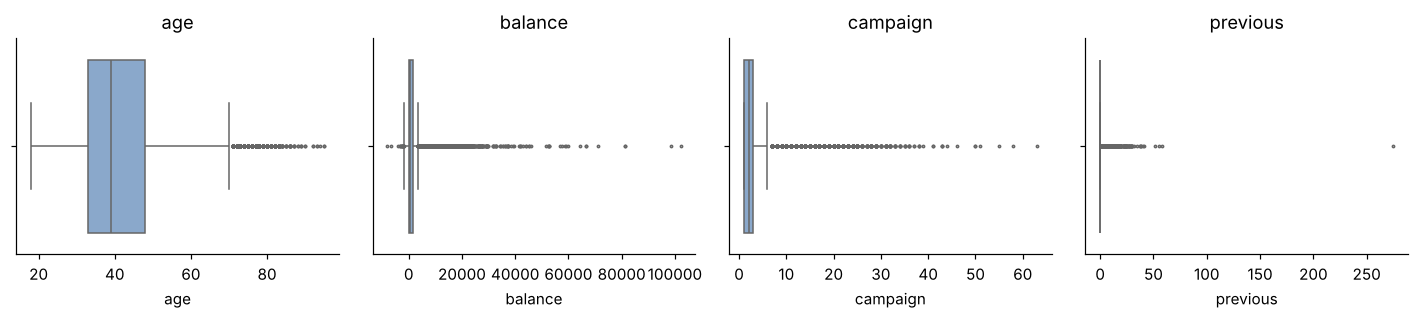

In [5]:
out_cols = ["age", "balance", "campaign", "previous", "duration"]
rows = []
for c in out_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, lo, hi, int(((df[c] < lo) | (df[c] > hi)).sum()), ((df[c] < lo) | (df[c] > hi)).mean() * 100])
outl = pd.DataFrame(rows, columns=["feature", "lower", "upper", "n_outliers", "pct"]).round(2)
display(outl); RESULTS["outliers"] = outl.to_dict("records")

fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a, c in zip(ax, ["age", "balance", "campaign", "previous"]):
    sns.boxplot(x=df[c], ax=a, color="#7fa7d6", fliersize=1.5); a.set_title(c)
save("lab1_outliers_boxplots.png")

**Treatment decision.** These outliers are real customers (a client really can hold a large balance or be called 40 times), so rows are **not deleted**. Instead, extreme values are **capped (winsorised) at the 1st and 99th percentiles of the training rows**. `balance` also gets a signed-log transform. Tree models are insensitive to outliers anyway; capping mainly protects the linear and neural models.

In [6]:
CAPS = {c: tuple(df.loc[IDX_TR, c].quantile([.01, .99])) for c in ["age", "balance", "campaign", "previous"]}   # training rows only
print({k: tuple(round(x, 1) for x in v) for k, v in CAPS.items()})

{'age': (23.0, 71.0), 'balance': (-626.3, 13161.3), 'campaign': (1.0, 16.3), 'previous': (0.0, 9.0)}


## 1.3 Distributions

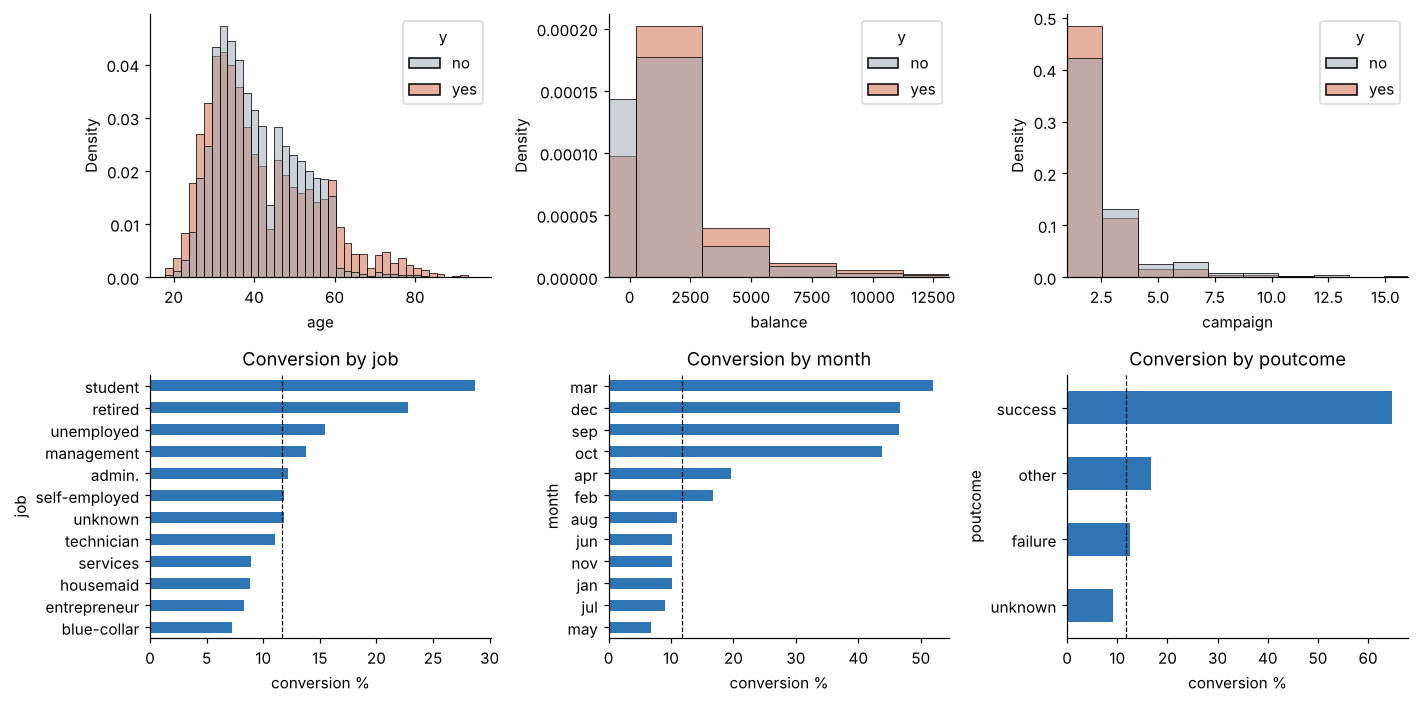

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
for a, c in zip(ax[0], ["age", "balance", "campaign"]):
    sns.histplot(data=df, x=c, hue="y", bins=40, stat="density", common_norm=False, ax=a,
                 palette={"no": "#9aa5b1", "yes": "#d1603d"})
    if c != "age": a.set_xlim(df[c].quantile(.005), df[c].quantile(.99))
for a, c in zip(ax[1], ["job", "month", "poutcome"]):
    r = df.groupby(c)["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values()
    r.plot.barh(ax=a, color="#2e75b6"); a.axvline(11.7, ls="--", c="k", lw=.8)
    a.set_xlabel("conversion %"); a.set_title(f"Conversion by {c}")
save("lab1_distributions.png")
mrate = df.groupby("month")["y"].apply(lambda s: (s == "yes").mean())
RESULTS["month_conv_min_max"] = [float(mrate.min()), float(mrate.max())]

## 1.4 Feature engineering and converting categorical data to numerical

In [8]:
MONTHS = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
EDU = {"primary": 1, "secondary": 2, "tertiary": 3, "unknown": np.nan}

def engineer(d, caps=CAPS):
    d = d.copy()
    for c, (lo, hi) in caps.items(): d[c] = d[c].clip(lo, hi)            # outlier capping
    for c in ["default", "housing", "loan"]: d[c] = (d[c] == "yes").astype(int)  # binary -> 0/1
    d["education_level"] = d["education"].map(EDU)                       # ordinal encoding
    for c in ["job", "education", "contact", "poutcome"]:                 # informative missingness
        d[f"unk_{c}"] = (d[c] == "unknown").astype(int)
    d["never_contacted"] = (d.pdays == -1).astype(int)                   # sentinel recoding
    d["days_since_contact"] = d.pdays.where(d.pdays >= 0)
    d["total_contacts"] = d.campaign + d.previous
    d["prior_success"] = (d.poutcome == "success").astype(int)
    d["balance_slog"] = np.sign(d.balance) * np.log1p(np.abs(d.balance))
    d["negative_balance"] = (d.balance < 0).astype(int)
    m = d.month.map({m: i for i, m in enumerate(MONTHS)})
    d["month_sin"], d["month_cos"] = np.sin(2*np.pi*m/12), np.cos(2*np.pi*m/12)  # cyclical encoding
    d["day_sin"], d["day_cos"] = np.sin(2*np.pi*d.day/31), np.cos(2*np.pi*d.day/31)
    return d

D = engineer(df)
y = (D.pop("y") == "yes").astype(int).values
duration = D.pop("duration")
NOMINAL = ["job", "marital", "education", "contact", "month", "poutcome"]
NUMERIC = [c for c in D.columns if c not in NOMINAL]
print(len(NOMINAL), "nominal +", len(NUMERIC), "numeric columns:", NUMERIC)

def make_pre(scale=True):
    num = Pipeline([("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else []))
    return ColumnTransformer([("num", num, NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL)])
Xall = make_pre().fit_transform(D)
_enc = make_pre().fit(D).named_transformers_["cat"]
feat_names = NUMERIC + list(_enc.get_feature_names_out(NOMINAL))
# Parent attribute of every encoded column (by position, not by name prefix: e.g. month_sin is NOT part of 'month').
FEAT_GROUP = NUMERIC + [g for g, cats in zip(NOMINAL, _enc.categories_) for _ in cats]
assert len(FEAT_GROUP) == len(feat_names) and len(set(feat_names)) == len(feat_names)
print("Final model matrix:", Xall.shape)
RESULTS["n_features_encoded"] = Xall.shape[1]

6 nominal + 24 numeric columns: ['age', 'default', 'balance', 'housing', 'loan', 'day', 'campaign', 'pdays', 'previous', 'education_level', 'unk_job', 'unk_education', 'unk_contact', 'unk_poutcome', 'never_contacted', 'days_since_contact', 'total_contacts', 'prior_success', 'balance_slog', 'negative_balance', 'month_sin', 'month_cos', 'day_sin', 'day_cos']


Final model matrix: (45211, 62)


## 1.5 Correlation analysis

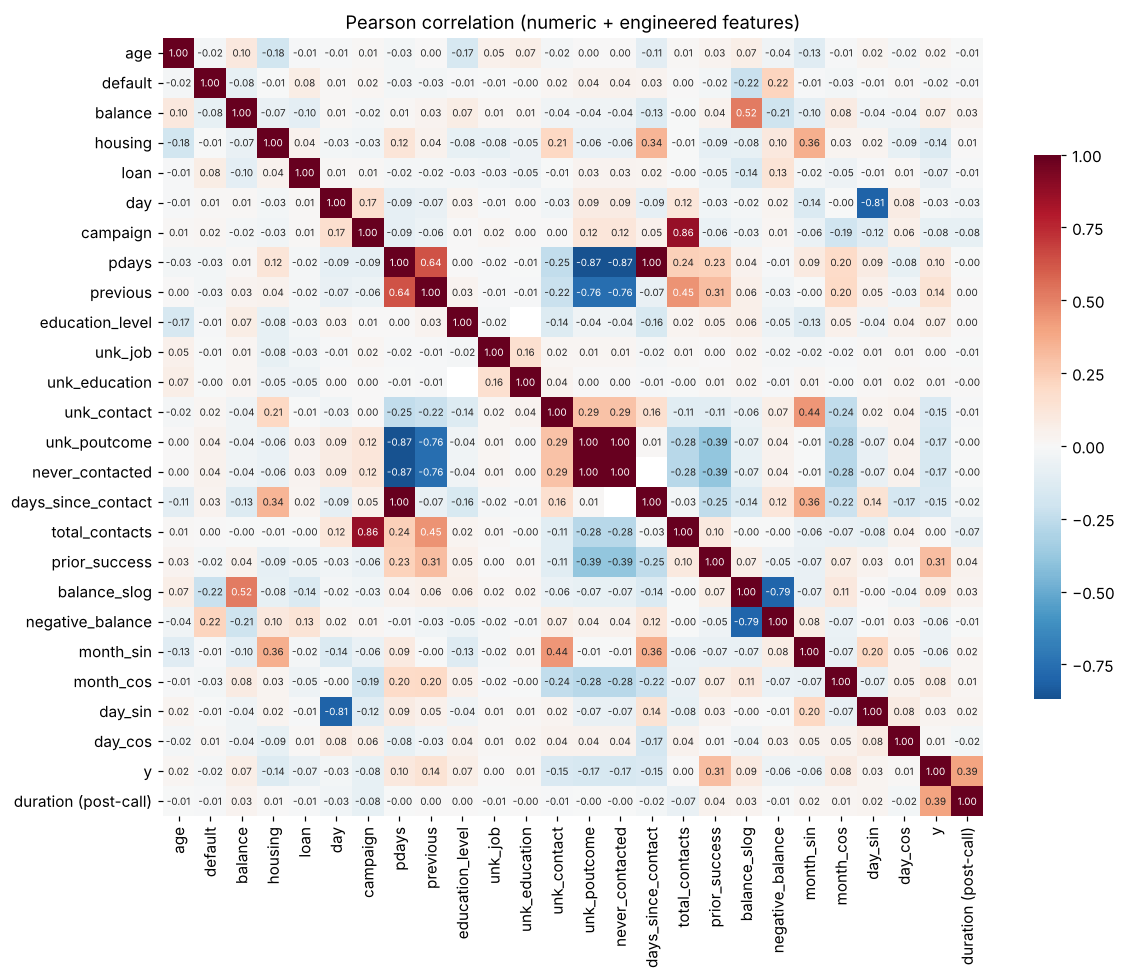

duration (post-call)    0.395
prior_success           0.307
never_contacted        -0.167
unk_poutcome           -0.167
days_since_contact     -0.152
unk_contact            -0.151
previous                0.142
housing                -0.139
pdays                   0.104
balance_slog            0.091
Name: y, dtype: float64

Highly correlated pairs (|r|>0.8): [('day', 'day_sin', np.float64(-0.808)), ('campaign', 'total_contacts', np.float64(0.865)), ('pdays', 'unk_poutcome', np.float64(-0.87)), ('pdays', 'never_contacted', np.float64(-0.87)), ('pdays', 'days_since_contact', np.float64(1.0)), ('unk_poutcome', 'never_contacted', np.float64(1.0))]


In [9]:
num_view = D[NUMERIC].copy(); num_view["y"] = y; num_view["duration (post-call)"] = duration.values
corr = num_view.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 6.5}, cbar_kws={"shrink": .7})
plt.title("Pearson correlation (numeric + engineered features)")
save("lab1_correlation_heatmap.png")
tc = corr["y"].drop("y").sort_values(key=abs, ascending=False)
display(tc.head(10).round(3)); RESULTS["top_corr_with_target"] = tc.head(10).round(4).to_dict()
hi_pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr) for b in corr.columns[i+1:]
            if abs(corr.loc[a, b]) > .8 and "y" not in (a, b)]
print("Highly correlated pairs (|r|>0.8):", hi_pairs)

Most numeric features have only weak linear correlation with the target. `duration` is the strongest (≈0.39), which is exactly the leakage problem: it measures the outcome of the call. `prior_success`, `never_contacted` and `days_since_contact` are the strongest **pre-call** signals. The highly correlated pairs are expected redundancies (for example `pdays` and `never_contacted`), which motivates feature selection.

## 1.6 Feature selection — mutual information and chi-square

,feature,mutual_info,chi2
17,prior_success,0.0307,22883.8943
7,pdays,0.0273,1179.8410
60,poutcome_success,0.0271,4113.0006
15,days_since_contact,0.0258,22.2657
2,balance,0.0228,232.8471
18,balance_slog,0.0220,124.9025
61,poutcome_unknown,0.0201,230.2797
43,contact_cellular,0.0180,294.0171
45,contact_unknown,0.0166,733.3549
12,unk_contact,0.0160,1619.5173


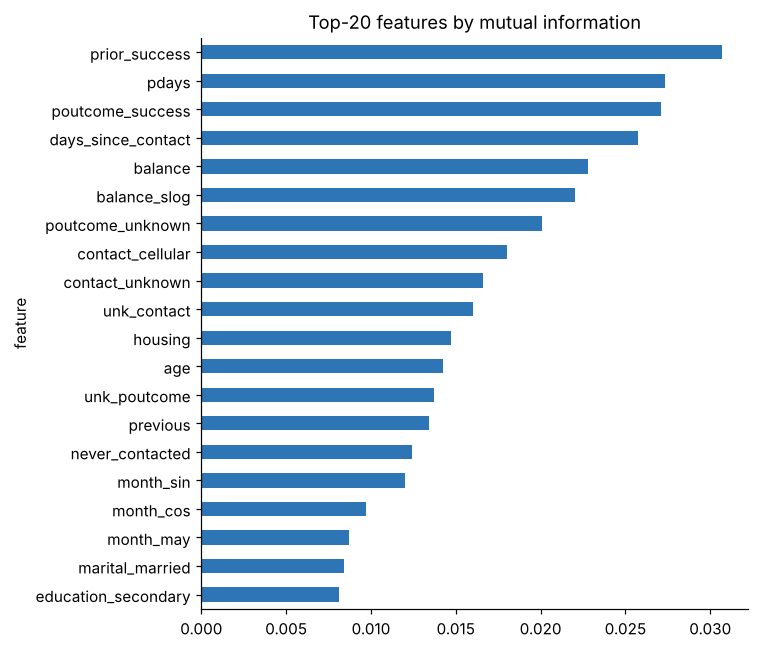

In [10]:
mi = mutual_info_classif(Xall, y, random_state=SEED)
Xpos = Xall - Xall.min(axis=0)
ch = chi2(Xpos, y)[0]
fs = pd.DataFrame({"feature": feat_names, "mutual_info": mi, "chi2": ch}).sort_values("mutual_info", ascending=False)
display(fs.head(15).round(4))
fs.head(20).plot.barh(x="feature", y="mutual_info", figsize=(7, 6), legend=False, color="#2e75b6").invert_yaxis()
plt.title("Top-20 features by mutual information"); save("lab1_mutual_info.png")
RESULTS["mi_top15"] = fs.head(15)["feature"].tolist()

## 1.7 Principal Component Analysis

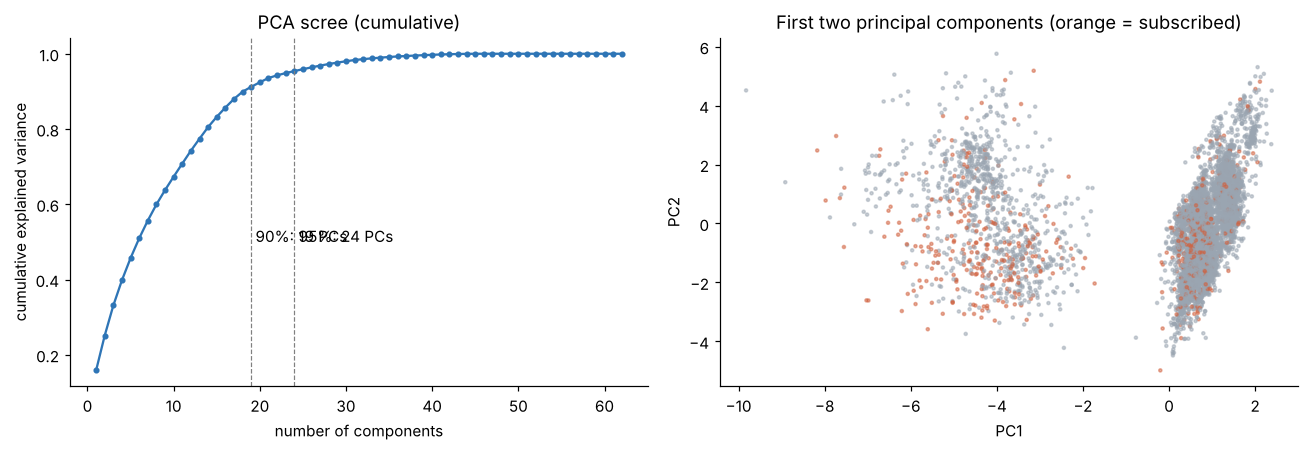

62 features -> 90% variance needs 19 PCs, 95% needs 24
{'all features': np.float64(0.7662), 'PCA 19 comps (90% var)': np.float64(0.7415)}


In [11]:
pca = PCA().fit(Xall)
cum = np.cumsum(pca.explained_variance_ratio_)
k90, k95 = int(np.argmax(cum >= .90) + 1), int(np.argmax(cum >= .95) + 1)
Z = PCA(2, random_state=SEED).fit_transform(Xall)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(range(1, len(cum)+1), cum, marker=".", c="#2e75b6")
for k, l in [(k90, "90%"), (k95, "95%")]: ax[0].axvline(k, ls="--", c="grey", lw=.8); ax[0].text(k+.5, .5, f"{l}: {k} PCs")
ax[0].set(xlabel="number of components", ylabel="cumulative explained variance", title="PCA scree (cumulative)")
idx = np.random.RandomState(SEED).choice(len(Z), 6000, replace=False)
ax[1].scatter(Z[idx, 0], Z[idx, 1], c=np.where(y[idx] == 1, "#d1603d", "#9aa5b1"), s=4, alpha=.5)
ax[1].set(title="First two principal components (orange = subscribed)", xlabel="PC1", ylabel="PC2")
save("lab1_pca.png")

cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
pca_res = {}   # CV on training rows only; scaling and PCA are fitted inside each fold
for name, steps in [("all features", []), (f"PCA {k90} comps (90% var)", [("pca", PCA(k90, random_state=SEED))])]:
    pipe = Pipeline([("pre", make_pre())] + steps + [("lr", LogisticRegression(max_iter=2000))])
    pca_res[name] = cross_val_score(pipe, D.loc[IDX_TR], y[IDX_TR], cv=cv5, scoring="roc_auc").mean()
print(f"{Xall.shape[1]} features -> 90% variance needs {k90} PCs, 95% needs {k95}")
print({k: round(v, 4) for k, v in pca_res.items()})
RESULTS["pca"] = {"n_features": Xall.shape[1], "k90": k90, "k95": k95, "lr_auc": pca_res}

PCA compresses the feature space, but the two classes overlap heavily in the first two components, so this problem is not linearly separable in a low-dimensional projection. Dropping to the 90%-variance components costs some AUC, because PCA keeps directions of high *variance*, not of high *predictive value*. For that reason PCA is used here for analysis, and supervised selection (Section 5, GA) is used for the final model.

# Train / test protocol
Everything below uses one stratified 80/20 split. Model selection, tuning, threshold choice and GA search use **only the 80% training part** with cross-validation (5-fold; 3-fold inside Optuna tuning and the GA). Outlier caps and the two EDA model checks above also used training rows only. The 20% test set is touched once, at the end, for the reported numbers.

In [12]:
D_tr, D_te, y_tr, y_te, dur_tr, dur_te = train_test_split(D, y, duration.values, test_size=.2,
                                                          stratify=y, random_state=SEED)
assert (D_tr.index == IDX_TR).all() and (D_te.index == IDX_TE).all()   # same split as used for the caps
print(D_tr.shape, D_te.shape, y_tr.mean().round(4), y_te.mean().round(4))

def evaluate(p, yt, thr=0.5):
    pred = (p >= thr).astype(int)
    order = np.argsort(-p); top = order[: int(.1 * len(p))]
    return {"roc_auc": roc_auc_score(yt, p), "pr_auc": average_precision_score(yt, p),
            "precision": precision_score(yt, pred, zero_division=0), "recall": recall_score(yt, pred),
            "f1": f1_score(yt, pred), "mcc": matthews_corrcoef(yt, pred), "brier": brier_score_loss(yt, p),
            "top10_capture": yt[top].sum() / yt.sum(), "threshold": thr,
            "accuracy": accuracy_score(yt, pred), "balanced_accuracy": balanced_accuracy_score(yt, pred),
            "tp": int(((pred == 1) & (yt == 1)).sum()), "fp": int(((pred == 1) & (yt == 0)).sum()),
            "fn": int(((pred == 0) & (yt == 1)).sum()), "tn": int(((pred == 0) & (yt == 0)).sum())}

(36168, 30) (9043, 30) 0.117 0.117


# 2. Lab 3 — Regularization (L1, L2, ElasticNet)

,penalty,C,train_auc,cv_auc,nonzero_coefs,gap
0,l1,0.001,0.7055,0.7055,3,-0.0000
1,l1,0.010,0.7494,0.7477,22,0.0017
2,l1,0.100,0.7708,0.7672,39,0.0037
3,l1,1.000,0.7708,0.7664,46,0.0044
4,l1,10.000,0.7707,0.7662,60,0.0046
5,l2,0.001,0.7546,0.7522,62,0.0025
6,l2,0.010,0.7683,0.7646,62,0.0037
7,l2,0.100,0.7709,0.7665,62,0.0043
8,l2,1.000,0.7708,0.7662,62,0.0046
9,l2,10.000,0.7707,0.7661,62,0.0046


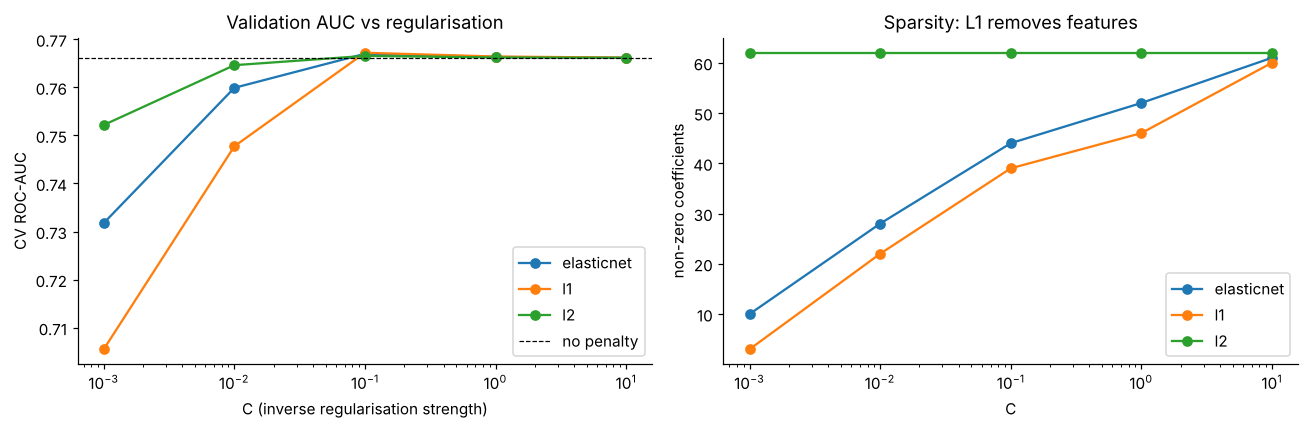

Best: {'penalty': 'l1', 'C': np.float64(0.1), 'train_auc': np.float64(0.7708383309488926), 'cv_auc': np.float64(0.7671858318927607), 'nonzero_coefs': np.int64(39), 'gap': np.float64(0.0036524990561319637)}


In [13]:
reg_rows, coef_path = [], []
Cs = [0.001, 0.01, 0.1, 1, 10]
for pen in ["l1", "l2", "elasticnet"]:
    for C in Cs:
        clf = LogisticRegression(penalty=pen, C=C, solver="saga", l1_ratio=.5 if pen == "elasticnet" else None,
                                 max_iter=3000, tol=1e-3)
        pipe = Pipeline([("pre", make_pre()), ("clf", clf)])
        cv = __import__("sklearn.model_selection", fromlist=["cross_validate"]).cross_validate(
            pipe, D_tr, y_tr, cv=cv5, scoring="roc_auc", return_train_score=True)
        pipe.fit(D_tr, y_tr); nz = int((np.abs(pipe["clf"].coef_) > 1e-6).sum())
        reg_rows.append([pen, C, cv["train_score"].mean(), cv["test_score"].mean(), nz])
none = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(penalty=None, max_iter=3000))])
cvn = __import__("sklearn.model_selection", fromlist=["cross_validate"]).cross_validate(
    none, D_tr, y_tr, cv=cv5, scoring="roc_auc", return_train_score=True)
reg_rows.append(["none", np.nan, cvn["train_score"].mean(), cvn["test_score"].mean(), Xall.shape[1]])
reg = pd.DataFrame(reg_rows, columns=["penalty", "C", "train_auc", "cv_auc", "nonzero_coefs"])
reg["gap"] = reg.train_auc - reg.cv_auc
display(reg.round(4)); RESULTS["regularization"] = reg.round(5).to_dict("records")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for pen, g in reg[reg.penalty != "none"].groupby("penalty"):
    ax[0].plot(g.C, g.cv_auc, marker="o", label=pen); ax[1].plot(g.C, g.nonzero_coefs, marker="o", label=pen)
ax[0].axhline(cvn["test_score"].mean(), ls="--", c="k", lw=.8, label="no penalty")
ax[0].set(xscale="log", xlabel="C (inverse regularisation strength)", ylabel="CV ROC-AUC", title="Validation AUC vs regularisation")
ax[1].set(xscale="log", xlabel="C", ylabel="non-zero coefficients", title="Sparsity: L1 removes features")
ax[0].legend(); ax[1].legend(); save("lab3_regularization.png")
best_reg = reg.sort_values("cv_auc", ascending=False).iloc[0]; print("Best:", dict(best_reg))

The train–validation gap is small for every setting, so logistic regression on this data does not overfit badly. Its limit is **underfitting**: it is a linear model. Strong regularisation (small C) hurts AUC. L1 is useful because it drops many one-hot columns to exactly zero while keeping almost the same AUC, which makes it a free feature selector. This is used as a baseline for the GA in Section 5.

# 3. Lab 4 — Classification and evaluation
## 3.1 The 2014 baselines vs modern ensembles (5-fold CV on the training set)

In [14]:
def lgbm(**kw):
    base = dict(n_estimators=400, learning_rate=.05, num_leaves=31, subsample=.8, subsample_freq=1,
                colsample_bytree=.8, random_state=SEED, verbose=-1, n_jobs=2)
    base.update(kw); return lgb.LGBMClassifier(**base)

models = {
    "Logistic Regression (2014)": (make_pre(), LogisticRegression(C=float(best_reg.C) if best_reg.penalty!="none" else 1.0,
                                     penalty=best_reg.penalty if best_reg.penalty!="none" else None,
                                     solver="saga", l1_ratio=.5 if best_reg.penalty=="elasticnet" else None, max_iter=3000, tol=1e-3)),
    "Decision Tree (2014)": (make_pre(False), DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)),
    "Neural Network / MLP (2014)": (make_pre(), MLPClassifier((64, 32), alpha=1e-2, early_stopping=True, max_iter=300, random_state=SEED)),
    "Linear SVM (2014)": (make_pre(), CalibratedClassifierCV(LinearSVC(C=.1, dual=False), cv=3)),
    "Random Forest": (make_pre(False), RandomForestClassifier(400, min_samples_leaf=5, n_jobs=2, random_state=SEED)),
    "Hist Gradient Boosting": (make_pre(False), HistGradientBoostingClassifier(max_iter=400, learning_rate=.05, random_state=SEED)),
    "LightGBM": (make_pre(False), lgbm()),
}
cmp_rows, OOF = [], {}
for name, (pre, clf) in models.items():
    t = time.time()
    p = cross_val_predict(Pipeline([("pre", pre), ("clf", clf)]), D_tr, y_tr, cv=cv5, method="predict_proba")[:, 1]
    OOF[name] = p; r = evaluate(p, y_tr); r.update(model=name, seconds=time.time() - t); cmp_rows.append(r)
    print(f"{name:30s} AUC {r['roc_auc']:.4f}  PR-AUC {r['pr_auc']:.4f}  recall@0.5 {r['recall']:.3f}  ({r['seconds']:.0f}s)")
cmp = pd.DataFrame(cmp_rows).set_index("model"); RESULTS["model_comparison_cv"] = cmp.round(5).reset_index().to_dict("records")

Logistic Regression (2014)     AUC 0.7671  PR-AUC 0.4063  recall@0.5 0.172  (5s)


Decision Tree (2014)           AUC 0.7112  PR-AUC 0.3406  recall@0.5 0.195  (1s)


Neural Network / MLP (2014)    AUC 0.7878  PR-AUC 0.4303  recall@0.5 0.232  (12s)


Linear SVM (2014)              AUC 0.7626  PR-AUC 0.4014  recall@0.5 0.196  (3s)


Random Forest                  AUC 0.8008  PR-AUC 0.4542  recall@0.5 0.199  (34s)


Hist Gradient Boosting         AUC 0.7988  PR-AUC 0.4510  recall@0.5 0.224  (6s)


LightGBM                       AUC 0.7971  PR-AUC 0.4468  recall@0.5 0.258  (6s)


## 3.2 Class imbalance handling (on LightGBM)

In [15]:
imb_set = {
    "none": ImbPipeline([("pre", make_pre(False)), ("clf", lgbm())]),
    "class weights": ImbPipeline([("pre", make_pre(False)), ("clf", lgbm(class_weight="balanced"))]),
    "SMOTE (inside CV)": ImbPipeline([("pre", make_pre(False)), ("sm", SMOTE(random_state=SEED)), ("clf", lgbm())]),
    "random undersampling": ImbPipeline([("pre", make_pre(False)), ("rus", RandomUnderSampler(random_state=SEED)), ("clf", lgbm())]),
}
imb_rows = []
for name, pipe in imb_set.items():
    p = cross_val_predict(pipe, D_tr, y_tr, cv=cv5, method="predict_proba")[:, 1]
    r = evaluate(p, y_tr); r["strategy"] = name; imb_rows.append(r)
imb = pd.DataFrame(imb_rows).set_index("strategy")
display(imb[["roc_auc", "pr_auc", "precision", "recall", "f1"]].round(4))
RESULTS["imbalance_cv"] = imb.round(5).reset_index().to_dict("records")

,roc_auc,pr_auc,precision,recall,f1
strategy,,,,,
none,0.7971,0.4468,0.6058,0.2579,0.3617
class weights,0.7955,0.4516,0.3733,0.6043,0.4615
SMOTE (inside CV),0.7974,0.4470,0.6105,0.2560,0.3607
random undersampling,0.7859,0.4179,0.2903,0.6653,0.4042


Rebalancing barely changes the ranking quality (ROC-AUC), but it moves the operating point a lot: recall at the default 0.5 threshold jumps with class weighting or undersampling (SMOTE inside the fold changes it little for LightGBM). The same effect can be obtained more cleanly by **tuning the decision threshold** on the unbalanced model, which also keeps the probabilities calibrated. The final model uses that approach.

## 3.3 Building the improved model: Optuna-tuned LightGBM, XGBoost, CatBoost and ensembles
Three gradient-boosting libraries are tuned or configured, then combined. The final model is chosen by **cross-validated PR-AUC on the training set**, never by the test set.

In [16]:
import optuna, xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.base import BaseEstimator, ClassifierMixin, clone
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
Xtr_t = make_pre(False).fit(D_tr).transform(D_tr)

def xgbm(**kw):
    return xgb.XGBClassifier(**{**dict(tree_method="hist", random_state=SEED, n_jobs=2, eval_metric="logloss"), **kw})

def obj_lgb(t):
    p = dict(n_estimators=t.suggest_int("n_estimators", 200, 1200), learning_rate=t.suggest_float("learning_rate", .01, .1, log=True),
             num_leaves=t.suggest_int("num_leaves", 8, 96), min_child_samples=t.suggest_int("min_child_samples", 10, 200),
             colsample_bytree=t.suggest_float("colsample_bytree", .3, 1), subsample=t.suggest_float("subsample", .5, 1),
             reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True), reg_alpha=t.suggest_float("reg_alpha", 1e-3, 10, log=True))
    return cross_val_score(lgbm(**p), Xtr_t, y_tr, cv=cv3, scoring="average_precision").mean()
def obj_xgb(t):
    p = dict(n_estimators=t.suggest_int("n_estimators", 200, 1200), learning_rate=t.suggest_float("learning_rate", .01, .1, log=True),
             max_depth=t.suggest_int("max_depth", 3, 9), min_child_weight=t.suggest_float("min_child_weight", 1, 20, log=True),
             colsample_bytree=t.suggest_float("colsample_bytree", .3, 1), subsample=t.suggest_float("subsample", .5, 1),
             reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True), gamma=t.suggest_float("gamma", 1e-3, 5, log=True))
    return cross_val_score(xgbm(**p), Xtr_t, y_tr, cv=cv3, scoring="average_precision").mean()

t = time.time()
st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(obj_lgb, n_trials=40)
BEST_LGB = st.best_params; print(f"Optuna LightGBM ({time.time()-t:.0f}s):", BEST_LGB)
t = time.time()
st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)); st.optimize(obj_xgb, n_trials=40)
BEST_XGB = st.best_params; print(f"Optuna XGBoost ({time.time()-t:.0f}s):", BEST_XGB)
RESULTS["tuned_lgbm_params"] = BEST_LGB; RESULTS["tuned_xgb_params"] = BEST_XGB

class Blend(BaseEstimator, ClassifierMixin):
    # Equal-weight average of predicted probabilities of several fitted models.
    def __init__(self, members): self.members = members
    def fit(self, X, y):
        self.fitted_ = [clone(m).fit(X, y) for m in self.members]; self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.fitted_], axis=0); return np.column_stack([1 - p, p])
    def predict(self, X): return (self.predict_proba(X)[:, 1] >= .5).astype(int)

class CatBoostWrap(BaseEstimator, ClassifierMixin):
    # sklearn-compatible wrapper: CatBoost receives the nominal columns natively (no one-hot encoding).
    def __init__(self, iterations=1000, learning_rate=.04, depth=6, l2_leaf_reg=5):
        self.iterations, self.learning_rate, self.depth, self.l2_leaf_reg = iterations, learning_rate, depth, l2_leaf_reg
    def fit(self, X, y):
        self.model_ = CatBoostClassifier(iterations=self.iterations, learning_rate=self.learning_rate, depth=self.depth,
                                         l2_leaf_reg=self.l2_leaf_reg, random_seed=SEED, verbose=0, thread_count=2,
                                         cat_features=NOMINAL).fit(X, y)
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X): return self.model_.predict_proba(X)
    def predict(self, X): return (self.predict_proba(X)[:, 1] >= .5).astype(int)

CANDIDATES = {
    "Tuned LightGBM": lambda: Pipeline([("pre", make_pre(False)), ("clf", lgbm(**BEST_LGB))]),
    "Tuned XGBoost": lambda: Pipeline([("pre", make_pre(False)), ("clf", xgbm(**BEST_XGB))]),
    "CatBoost": lambda: CatBoostWrap(),
    "Stacked ensemble (LGB+HGB+LR)": lambda: Pipeline([("pre", make_pre()), ("stack", StackingClassifier(
        estimators=[("lgbm", lgbm(**BEST_LGB)),
                    ("hgb", HistGradientBoostingClassifier(max_iter=400, learning_rate=.05, random_state=SEED)),
                    ("lr", LogisticRegression(max_iter=3000))],
        final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba", n_jobs=1))]),
}
for name, mk in CANDIDATES.items():
    t = time.time(); p = cross_val_predict(mk(), D_tr, y_tr, cv=cv5, method="predict_proba")[:, 1]
    OOF[name] = p; r = evaluate(p, y_tr); r["model"] = name; cmp.loc[name] = pd.Series(r)
    print(f"{name:32s} CV AUC {r['roc_auc']:.4f}  PR-AUC {r['pr_auc']:.4f}  ({time.time()-t:.0f}s)")

BLENDS = {"Blend LightGBM+CatBoost": ["Tuned LightGBM", "CatBoost"],
          "Blend XGBoost+CatBoost": ["Tuned XGBoost", "CatBoost"],
          "Blend LightGBM+XGBoost+CatBoost": ["Tuned LightGBM", "Tuned XGBoost", "CatBoost"]}
for name, parts in BLENDS.items():
    CANDIDATES[name] = (lambda parts=parts: Blend([CANDIDATES[q]() for q in parts]))
    p = np.mean([OOF[q] for q in parts], axis=0); OOF[name] = p
    r = evaluate(p, y_tr); r["model"] = name; cmp.loc[name] = pd.Series(r)
    print(f"{name:32s} CV AUC {r['roc_auc']:.4f}  PR-AUC {r['pr_auc']:.4f}")

cand = cmp.loc[list(CANDIDATES)].sort_values(["pr_auc", "roc_auc"], ascending=False)
FINAL_NAME = cand.index[0]
print("\nSelected by CV PR-AUC ->", FINAL_NAME)
RESULTS["candidates_cv"] = cand[["roc_auc", "pr_auc"]].round(5).reset_index().to_dict("records")
RESULTS["final_model_name"] = FINAL_NAME
OOF["Final model (ours)"] = OOF[FINAL_NAME]

Optuna LightGBM (213s): {'n_estimators': 658, 'learning_rate': 0.013750514178225346, 'num_leaves': 42, 'min_child_samples': 105, 'colsample_bytree': 0.3578176615302694, 'subsample': 0.849485901430449, 'reg_lambda': 8.816201598136837, 'reg_alpha': 0.3876816312530815}


Optuna XGBoost (239s): {'n_estimators': 1108, 'learning_rate': 0.021291576103677164, 'max_depth': 9, 'min_child_weight': 16.74961825247582, 'colsample_bytree': 0.5092894667243373, 'subsample': 0.7484934191948245, 'reg_lambda': 0.026832040023118068, 'gamma': 2.2914171597434003}


Tuned LightGBM                   CV AUC 0.8040  PR-AUC 0.4608  (14s)


Tuned XGBoost                    CV AUC 0.8022  PR-AUC 0.4552  (11s)


CatBoost                         CV AUC 0.8040  PR-AUC 0.4547  (130s)


Stacked ensemble (LGB+HGB+LR)    CV AUC 0.8039  PR-AUC 0.4600  (110s)
Blend LightGBM+CatBoost          CV AUC 0.8058  PR-AUC 0.4616
Blend XGBoost+CatBoost           CV AUC 0.8050  PR-AUC 0.4589


Blend LightGBM+XGBoost+CatBoost  CV AUC 0.8053  PR-AUC 0.4608

Selected by CV PR-AUC -> Blend LightGBM+CatBoost


## 3.4 Choosing the decision threshold (on training OOF predictions only)

In [17]:
def best_f1_threshold(p, yt):
    pr, rc, th = precision_recall_curve(yt, p); f = 2*pr*rc/(pr+rc+1e-12)
    return float(th[np.argmax(f[:-1])])
THR = {name: best_f1_threshold(p, y_tr) for name, p in OOF.items()}
print({k: round(v, 3) for k, v in THR.items()})

{'Logistic Regression (2014)': 0.193, 'Decision Tree (2014)': 0.132, 'Neural Network / MLP (2014)': 0.216, 'Linear SVM (2014)': 0.148, 'Random Forest': 0.217, 'Hist Gradient Boosting': 0.182, 'LightGBM': 0.191, 'Tuned LightGBM': 0.19, 'Tuned XGBoost': 0.187, 'CatBoost': 0.218, 'Stacked ensemble (LGB+HGB+LR)': 0.131, 'Blend LightGBM+CatBoost': 0.188, 'Blend XGBoost+CatBoost': 0.191, 'Blend LightGBM+XGBoost+CatBoost': 0.186, 'Final model (ours)': 0.188}


## 3.5 Final evaluation on the untouched 20% test set

In [18]:
final = {}
FINAL_MODELS = {"Logistic Regression (2014)": models["Logistic Regression (2014)"],
                "Decision Tree (2014)": models["Decision Tree (2014)"],
                "Neural Network / MLP (2014)": models["Neural Network / MLP (2014)"],
                "Random Forest": models["Random Forest"], "LightGBM": models["LightGBM"]}
TEST_P = {}
for name, (pre, clf) in FINAL_MODELS.items():
    TEST_P[name] = Pipeline([("pre", pre), ("clf", clf)]).fit(D_tr, y_tr).predict_proba(D_te)[:, 1]
for name, mk in CANDIDATES.items():
    TEST_P[name] = mk().fit(D_tr, y_tr).predict_proba(D_te)[:, 1]
TEST_P["Final model (ours)"] = TEST_P[FINAL_NAME]

rows = []
for name, p in TEST_P.items():
    a = evaluate(p, y_te, 0.5); b = evaluate(p, y_te, THR[name])
    rows.append({"model": name, "roc_auc": a["roc_auc"], "pr_auc": a["pr_auc"], "brier": a["brier"],
                 "top10_capture": a["top10_capture"], "recall@0.5": a["recall"], "f1@0.5": a["f1"],
                 "threshold": THR[name], "precision@thr": b["precision"], "recall@thr": b["recall"],
                 "f1@thr": b["f1"], "mcc@thr": b["mcc"],
                 "precision@0.5": a["precision"], "accuracy@0.5": a["accuracy"], "bal_acc@0.5": a["balanced_accuracy"],
                 "accuracy@thr": b["accuracy"], "bal_acc@thr": b["balanced_accuracy"],
                 **{f"{k}@0.5": a[k] for k in ("tp", "fp", "fn", "tn")}, **{f"{k}@thr": b[k] for k in ("tp", "fp", "fn", "tn")}})
test = pd.DataFrame(rows).set_index("model")
display(test.round(4)); RESULTS["test_results"] = test.round(5).reset_index().to_dict("records")
RESULTS["test_set"] = {"n": int(len(y_te)), "positives": int(y_te.sum()), "always_no_accuracy": float(1 - y_te.mean())}
# Raw test-set predictions, so every reported test metric can be recomputed independently (verify_results.py)
pd.DataFrame({"y_true": y_te, **TEST_P}, index=D_te.index).to_csv(RES + "test_predictions.csv")
json.dump({"thresholds": THR}, open(RES + "thresholds.json", "w"), indent=1)

,roc_auc,pr_auc,brier,top10_capture,recall@0.5,f1@0.5,threshold,precision@thr,recall@thr,f1@thr,...,accuracy@thr,bal_acc@thr,tp@0.5,fp@0.5,fn@0.5,tn@0.5,tp@thr,fp@thr,fn@thr,tn@thr
model,,,,,,,,,,,,,,,,,,,,,
Logistic Regression (2014),0.7738,0.4143,0.0851,0.4197,0.1720,0.2737,0.1925,0.4476,0.4518,0.4497,...,0.8706,0.6890,182,90,876,7895,478,590,580,7395
Decision Tree (2014),0.7218,0.3221,0.0878,0.3819,0.2136,0.3181,0.1321,0.4894,0.3715,0.4224,...,0.8811,0.6601,226,137,832,7848,393,410,665,7575
Neural Network / MLP (2014),0.7940,0.4320,0.0831,0.4310,0.1928,0.2998,0.2165,0.4851,0.4603,0.4724,...,0.8797,0.6978,204,99,854,7886,487,517,571,7468
Random Forest,0.8071,0.4642,0.0803,0.4376,0.2004,0.3095,0.2170,0.4566,0.5614,0.5036,...,0.8705,0.7364,212,100,846,7885,594,707,464,7278
LightGBM,0.8049,0.4642,0.0801,0.4527,0.2656,0.3752,0.1907,0.4511,0.5586,0.4992,...,0.8688,0.7343,281,159,777,7826,591,719,467,7266
Tuned LightGBM,0.8096,0.4757,0.0799,0.4499,0.2476,0.3611,0.1904,0.4557,0.5586,0.5019,...,0.8703,0.7351,262,131,796,7854,591,706,467,7279
Tuned XGBoost,0.8098,0.4732,0.0801,0.4537,0.2439,0.3566,0.1867,0.4514,0.5482,0.4951,...,0.8692,0.7300,258,131,800,7854,580,705,478,7280
CatBoost,0.8079,0.4658,0.0798,0.4537,0.2741,0.3846,0.2182,0.4865,0.5265,0.5057,...,0.8796,0.7264,290,160,768,7825,557,588,501,7397
Stacked ensemble (LGB+HGB+LR),0.8093,0.4756,0.0812,0.4499,0.2552,0.3646,0.1314,0.4470,0.5624,0.4981,...,0.8674,0.7351,270,153,788,7832,595,736,463,7249


{
 "n_resamples": 1000,
 "delta_auc": 0.01667108108869444,
 "auc_ci95": [
  0.009834374803690014,
  0.023647859303502414
 ],
 "p_auc": 0.002,
 "delta_pr_auc": 0.042016218917127,
 "pr_auc_ci95": [
  0.027889697547136244,
  0.0553791502259434
 ],
 "p_pr": 0.0
}


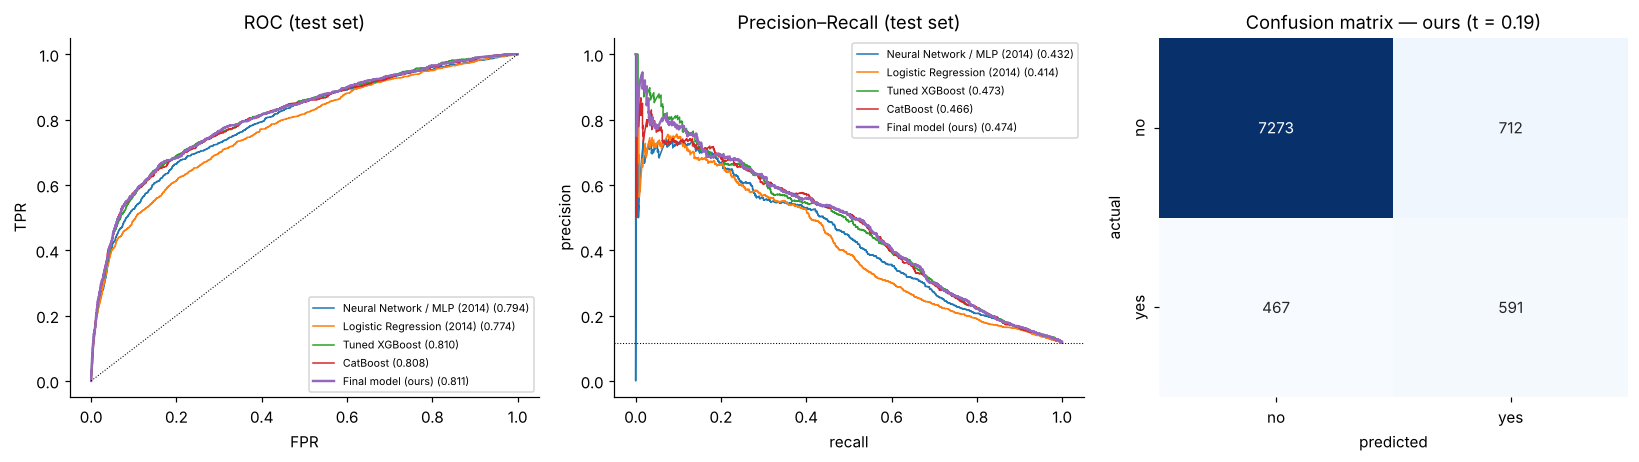

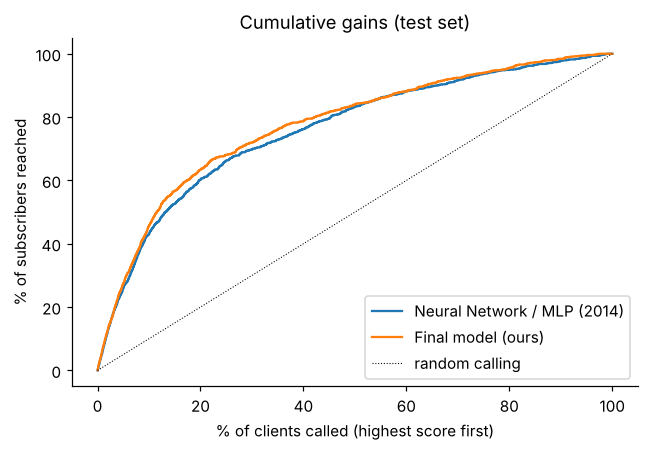

top 20%: {'Neural Network / MLP (2014)': 0.6011342155009451, 'Final model (ours)': 0.6342155009451795}
buyers reached by calling best 50%: {'Neural Network / MLP (2014)': 0.831758034026465, 'Final model (ours)': 0.8393194706994329}


In [19]:
best = "Final model (ours)"; base = "Neural Network / MLP (2014)"
# paired bootstrap on the test set: ours vs the 2014-style neural network
rng = np.random.RandomState(SEED); d_auc, d_pr = [], []
for _ in range(1000):
    i = rng.randint(0, len(y_te), len(y_te))
    if y_te[i].sum() == 0: continue
    d_auc.append(roc_auc_score(y_te[i], TEST_P[best][i]) - roc_auc_score(y_te[i], TEST_P[base][i]))
    d_pr.append(average_precision_score(y_te[i], TEST_P[best][i]) - average_precision_score(y_te[i], TEST_P[base][i]))
boot = {"n_resamples": len(d_auc), "delta_auc": float(np.mean(d_auc)), "auc_ci95": list(np.percentile(d_auc, [2.5, 97.5])),
        "p_auc": float(2 * min(np.mean(np.array(d_auc) <= 0), np.mean(np.array(d_auc) >= 0))),
        "delta_pr_auc": float(np.mean(d_pr)), "pr_auc_ci95": list(np.percentile(d_pr, [2.5, 97.5])),
        "p_pr": float(2 * min(np.mean(np.array(d_pr) <= 0), np.mean(np.array(d_pr) >= 0)))}
print(json.dumps(boot, indent=1)); RESULTS["bootstrap_ours_vs_mlp"] = boot

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for name in [base, "Logistic Regression (2014)", "Tuned XGBoost", "CatBoost", best]:
    fpr, tpr, _ = roc_curve(y_te, TEST_P[name]); ax[0].plot(fpr, tpr, lw=1.6 if name == best else 1, label=f"{name} ({roc_auc_score(y_te, TEST_P[name]):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, TEST_P[name]); ax[1].plot(rc, pr, lw=1.6 if name == best else 1, label=f"{name} ({average_precision_score(y_te, TEST_P[name]):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=.7); ax[0].set(title="ROC (test set)", xlabel="FPR", ylabel="TPR"); ax[0].legend(fontsize=7)
ax[1].axhline(y_te.mean(), ls=":", c="k", lw=.7); ax[1].set(title="Precision–Recall (test set)", xlabel="recall", ylabel="precision"); ax[1].legend(fontsize=7)
cm = confusion_matrix(y_te, (TEST_P[best] >= THR[best]).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[2], cbar=False, xticklabels=["no", "yes"], yticklabels=["no", "yes"])
ax[2].set(title=f"Confusion matrix — ours (t = {THR[best]:.2f})", xlabel="predicted", ylabel="actual")
save("lab4_test_curves.png")

# cumulative gains / lift
fig, ax = plt.subplots(figsize=(6, 4.2))
for name in [base, best]:
    o = np.argsort(-TEST_P[name]); g = np.cumsum(y_te[o]) / y_te.sum()
    ax.plot(np.arange(1, len(o)+1) / len(o) * 100, g * 100, label=name)
ax.plot([0, 100], [0, 100], "k:", lw=.7, label="random calling")
ax.set(xlabel="% of clients called (highest score first)", ylabel="% of subscribers reached", title="Cumulative gains (test set)")
ax.legend(); save("lab4_gains.png")
gains50 = {n: float(y_te[np.argsort(-TEST_P[n])[: len(y_te)//2]].sum() / y_te.sum()) for n in [base, best]}
gains20 = {n: float(y_te[np.argsort(-TEST_P[n])[: len(y_te)//5]].sum() / y_te.sum()) for n in [base, best]}
RESULTS["capture_top20pct"] = gains20; print("top 20%:", gains20)
RESULTS["capture_top50pct"] = gains50; print("buyers reached by calling best 50%:", gains50)

## 3.6 Leakage check — what `duration` would add (not deployable)

In [20]:
leak = {"duration_alone_auc_test": roc_auc_score(y_te, dur_te)}
Dd_tr, Dd_te = D_tr.assign(duration=dur_tr), D_te.assign(duration=dur_te)
NUMERIC_D = NUMERIC + ["duration"]
pre_d = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUMERIC_D),
                           ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL)])
pd_ = Pipeline([("pre", pre_d), ("clf", lgbm(**BEST_LGB))]).fit(Dd_tr, y_tr).predict_proba(Dd_te)[:, 1]
leak["with_duration_auc_test"] = roc_auc_score(y_te, pd_)
leak["without_duration_auc_test"] = roc_auc_score(y_te, TEST_P["Tuned LightGBM"])
print({k: round(v, 4) for k, v in leak.items()}); RESULTS["leakage"] = leak

{'duration_alone_auc_test': 0.8069, 'with_duration_auc_test': 0.9356, 'without_duration_auc_test': 0.8096}


`duration` alone ranks clients about as well as the whole published 2014 model, and adding it pushes AUC above 0.9. But the call length is only known after the call, so a model that uses it cannot choose whom to call. All results reported as **ours** exclude it.

# 4. Lab 5 — RFM features and K-Means customer segmentation

Adapting RFM to telemarketing:
* **Recency** = days since the client was last contacted in a previous campaign (never contacted → a large value, 999)
* **Frequency** = total number of contacts (this campaign + previous campaigns)
* **Monetary** = average yearly account balance

`age` is added as profile context. Recency, frequency and monetary are log-transformed, then all four are standardised. The number of clusters is chosen with the elbow (knee) rule and checked with the silhouette score. The target `y` is **not** used for clustering; it is only used afterwards to interpret the clusters.

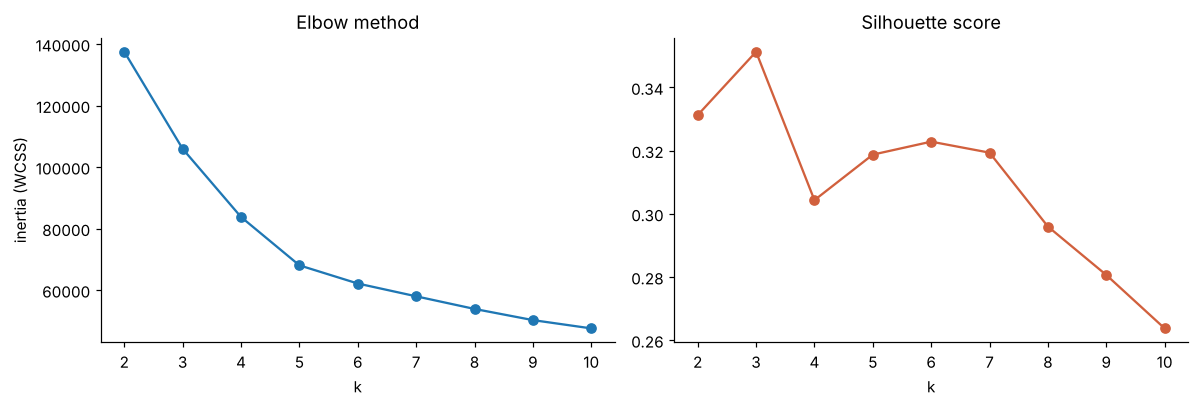

{2: 0.331, 3: 0.351, 4: 0.304, 5: 0.319, 6: 0.323, 7: 0.319, 8: 0.296, 9: 0.281, 10: 0.264}
elbow (knee) k = 5 | best-silhouette k = 3


In [21]:
rfm = pd.DataFrame({"recency": np.where(df.pdays >= 0, df.pdays, 999),
                    "frequency": df.campaign.clip(upper=CAPS["campaign"][1]) + df.previous.clip(upper=CAPS["previous"][1]),
                    "monetary": df.balance.clip(*CAPS["balance"]),
                    "age": df.age})
rfm_t = pd.DataFrame({"recency": np.log1p(rfm.recency), "frequency": np.log1p(rfm.frequency),
                      "monetary": np.sign(rfm.monetary) * np.log1p(np.abs(rfm.monetary)), "age": rfm.age})
Zr = StandardScaler().fit_transform(rfm_t)
sub = np.random.RandomState(SEED).choice(len(Zr), 8000, replace=False)
inertia, sil = [], []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Zr)
    inertia.append(km.inertia_); sil.append(silhouette_score(Zr[sub], km.labels_[sub]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(2, 11), inertia, marker="o"); ax[0].set(title="Elbow method", xlabel="k", ylabel="inertia (WCSS)")
ax[1].plot(range(2, 11), sil, marker="o", c="#d1603d"); ax[1].set(title="Silhouette score", xlabel="k")
save("lab5_elbow.png")
print({k: round(s, 3) for k, s in zip(range(2, 11), sil)})
# Knee of the elbow curve: the k farthest from the straight line joining the first and last points (normalised).
ks = np.arange(2, 11); xn = (ks - ks[0]) / (ks[-1] - ks[0])
yn = (np.array(inertia) - min(inertia)) / (max(inertia) - min(inertia))
K_ELBOW = int(ks[np.argmax((1 - xn) - yn)]); K_SIL = int(ks[np.argmax(sil)])
print("elbow (knee) k =", K_ELBOW, "| best-silhouette k =", K_SIL)
RESULTS["kmeans_selection"] = {"k_elbow": K_ELBOW, "k_best_silhouette": K_SIL,
                               "inertia": dict(zip(map(int, ks), map(float, inertia))), "silhouette": dict(zip(map(int, ks), map(float, sil)))}

,size,recency_median,frequency_mean,monetary_median,age_mean,never_contacted,prior_success,conversion,share
cluster,,,,,,,,,
3,6747,182.0,4.907,703.0,40.879,0.000,0.207,0.243,0.149
4,10221,999.0,2.033,763.0,53.515,0.972,0.006,0.111,0.226
1,15319,999.0,1.686,567.0,33.878,0.980,0.002,0.111,0.339
2,6659,999.0,7.381,464.0,39.544,0.943,0.003,0.069,0.147
0,6265,999.0,2.669,-50.0,39.215,0.915,0.002,0.058,0.139


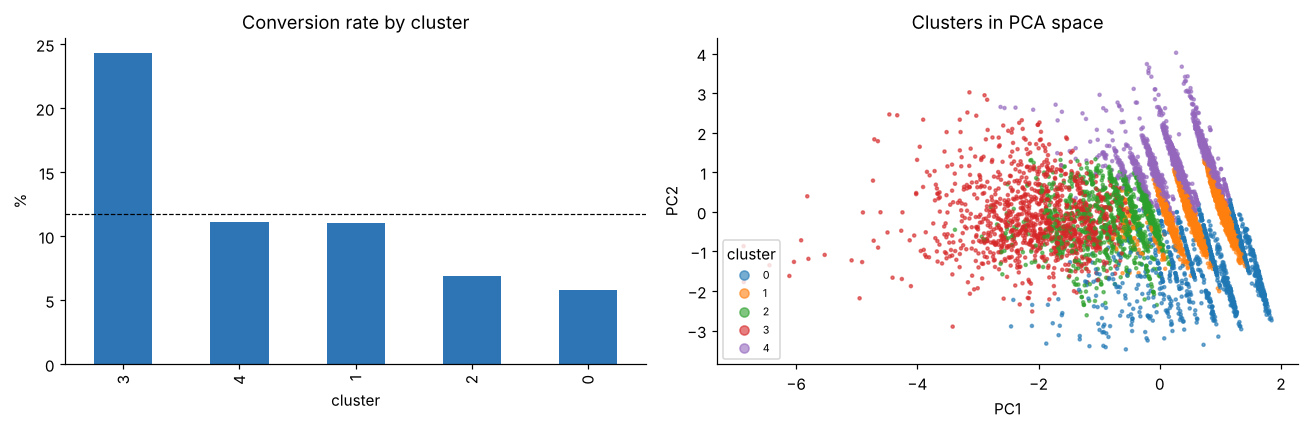

In [22]:
K = K_ELBOW   # chosen by the elbow (knee) rule; its silhouette is reported alongside
km = KMeans(K, n_init=20, random_state=SEED).fit(Zr)
seg = rfm.assign(cluster=km.labels_, subscribed=(df.y == "yes").astype(int),
                 never_contacted=(df.pdays == -1).astype(int), prior_success=(df.poutcome == "success").astype(int))
prof = seg.groupby("cluster").agg(size=("age", "size"), recency_median=("recency", "median"),
                                  frequency_mean=("frequency", "mean"), monetary_median=("monetary", "median"),
                                  age_mean=("age", "mean"), never_contacted=("never_contacted", "mean"),
                                  prior_success=("prior_success", "mean"), conversion=("subscribed", "mean"))
prof["share"] = prof["size"] / len(seg)
prof = prof.sort_values("conversion", ascending=False); display(prof.round(3))
RESULTS["kmeans"] = {"k": K, "silhouette": float(silhouette_score(Zr[sub], km.labels_[sub])), "silhouette_sample": len(sub),
                     "profiles": prof.round(4).reset_index().to_dict("records")}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
prof["conversion"].mul(100).plot.bar(ax=ax[0], color="#2e75b6"); ax[0].axhline(11.7, ls="--", c="k", lw=.8)
ax[0].set(title="Conversion rate by cluster", ylabel="%")
Z2 = PCA(2, random_state=SEED).fit_transform(Zr)
sc = ax[1].scatter(Z2[sub, 0], Z2[sub, 1], c=km.labels_[sub], cmap="tab10", vmin=0, vmax=9, s=4, alpha=.6)
ax[1].legend(*sc.legend_elements(), title="cluster", fontsize=7, loc="lower left")
ax[1].set(title="Clusters in PCA space", xlabel="PC1", ylabel="PC2")
save("lab5_clusters.png")

In [23]:
# Automatic naming + strategy from the profile (so the text always matches the numbers)
def describe(r):
    if r.never_contacted < .5 and r.prior_success > .1:
        return "Warm, previously converted", "Priority call list: call first, assign senior agents, offer renewal/upgrade rates."
    if r.never_contacted < .5:
        return "Recently re-contacted", "Second-touch campaign: reference the previous offer, use cellular channel."
    if r.frequency_mean > prof.frequency_mean.median() * 1.5:
        return "Over-called cold leads", "Cap call attempts at 3; move to email/SMS; avoid wasting agent time."
    if r.monetary_median < 100:
        return "Low/negative-balance cold prospects", "Lowest priority: cheap digital outreach only; call only when the model score is high."
    if r.age_mean >= 45:
        return "Older cold prospects with savings", "First-contact campaign with a secure, fixed-return deposit offer; prefer cellular contact and high-conversion months."
    return "Young cold prospects", "Mobile-first contact; starter deposit products; limit repeat calls to 2–3 attempts."
strat = pd.DataFrame([dict(cluster=c, **dict(zip(["segment", "strategy"], describe(r))),
                           share=r.share, conversion=r.conversion) for c, r in prof.iterrows()])
dup = strat.segment.duplicated(keep=False)   # keep names unique if two clusters fall under the same rule
strat.loc[dup, "segment"] = strat.loc[dup].apply(lambda r: f"{r.segment} (cluster {r.cluster})", axis=1)
display(strat); RESULTS["kmeans_strategy"] = strat.round(4).to_dict("records")

# Does the cluster label help the supervised model?
D_tr_c = D_tr.assign(cluster=km.labels_[D_tr.index].astype(str));
pre_c = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUMERIC),
                           ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL + ["cluster"])])
auc_c = cross_val_score(Pipeline([("pre", pre_c), ("clf", lgbm(**BEST_LGB))]), D_tr_c, y_tr, cv=cv5, scoring="roc_auc").mean()
auc_nc = cross_val_score(Pipeline([("pre", make_pre(False)), ("clf", lgbm(**BEST_LGB))]), D_tr, y_tr, cv=cv5, scoring="roc_auc").mean()
print(f"LightGBM CV AUC without cluster {auc_nc:.4f} | with cluster feature {auc_c:.4f}")
RESULTS["cluster_as_feature"] = {"without": auc_nc, "with": auc_c}

,cluster,segment,strategy,share,conversion
0,3,"Warm, previously converted","Priority call list: call first, assign senior ...",0.149234,0.242775
1,4,Older cold prospects with savings,"First-contact campaign with a secure, fixed-re...",0.226073,0.111242
2,1,Young cold prospects,Mobile-first contact; starter deposit products...,0.338833,0.110516
3,2,Over-called cold leads,Cap call attempts at 3; move to email/SMS; avo...,0.147287,0.068629
4,0,Low/negative-balance cold prospects,Lowest priority: cheap digital outreach only; ...,0.138572,0.058101


LightGBM CV AUC without cluster 0.8041 | with cluster feature 0.8038


# 5. Lab 7 — Genetic Algorithm feature selection
The GA searches over **feature groups** (each raw or engineered attribute, with all of its one-hot columns kept together), so a chromosome is a bit-string of length = number of attributes.

* **Fitness** = 3-fold CV ROC-AUC of a fast LightGBM on the training set − 0.002 × (number of selected attributes), which rewards accuracy and penalises complexity
* **Selection** = tournament (size 3); **crossover** = uniform (p = 0.8); **mutation** = bit-flip (p = 1/L); **elitism** = best 2 kept
* Population 20, 15 generations, with fitness caching

30 attributes in the search space


gen  0  best fitness 0.7661  mean 0.7474  n_attr 14


gen  1  best fitness 0.7668  mean 0.7572  n_attr 14


gen  2  best fitness 0.7668  mean 0.7602  n_attr 14


gen  3  best fitness 0.7668  mean 0.7635  n_attr 14


...

gen 11  best fitness 0.7777  mean 0.7712  n_attr 9


gen 12  best fitness 0.7783  mean 0.7741  n_attr 8


gen 13  best fitness 0.7783  mean 0.7754  n_attr 8


gen 14  best fitness 0.7783  mean 0.7749  n_attr 8



GA finished in 266s, 225 unique subsets evaluated
Selected 8/30 attributes: ['marital', 'contact', 'month', 'age', 'loan', 'day', 'pdays', 'prior_success']
Dropped: ['job', 'education', 'poutcome', 'default', 'balance', 'housing', 'campaign', 'previous', 'education_level', 'unk_job', 'unk_education', 'unk_contact', 'unk_poutcome', 'never_contacted', 'days_since_contact', 'total_contacts', 'balance_slog', 'negative_balance', 'month_sin', 'month_cos', 'day_sin', 'day_cos']


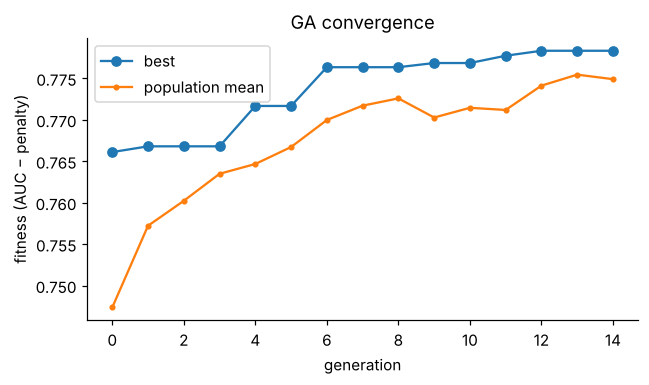

In [24]:
GROUPS = NOMINAL + NUMERIC
L = len(GROUPS); print(L, "attributes in the search space")
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
_cache = {}
def fitness(mask):
    key = tuple(mask)
    if key in _cache: return _cache[key]
    if mask.sum() == 0: return (0.0, 0.0)
    cols = [g for g, m in zip(GROUPS, mask) if m]
    nom, num = [c for c in cols if c in NOMINAL], [c for c in cols if c in NUMERIC]
    tr = []
    if num: tr.append(("num", SimpleImputer(strategy="median"), num))
    if nom: tr.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nom))
    pipe = Pipeline([("pre", ColumnTransformer(tr)), ("clf", lgbm(n_estimators=150, learning_rate=.08))])
    auc = cross_val_score(pipe, D_tr[cols], y_tr, cv=cv3, scoring="roc_auc").mean()
    _cache[key] = (auc - 0.002 * mask.sum(), auc); return _cache[key]

rng = np.random.RandomState(SEED)
POP, GENS, ELITE = 20, 15, 2
pop = (rng.rand(POP, L) < .6).astype(int); pop[0] = 1   # include the all-features individual
history = []; t0 = time.time()
for g in range(GENS):
    fit = np.array([fitness(ind)[0] for ind in pop])
    order = np.argsort(-fit); history.append((g, fit.max(), fit.mean(), int(pop[order[0]].sum())))
    new = [pop[i].copy() for i in order[:ELITE]]
    while len(new) < POP:
        p1 = pop[max(rng.choice(POP, 3), key=lambda i: fit[i])]
        p2 = pop[max(rng.choice(POP, 3), key=lambda i: fit[i])]
        child = np.where(rng.rand(L) < .5, p1, p2) if rng.rand() < .8 else p1.copy()
        flip = rng.rand(L) < 1 / L; child[flip] = 1 - child[flip]
        new.append(child)
    pop = np.array(new)
    print(f"gen {g:2d}  best fitness {fit.max():.4f}  mean {fit.mean():.4f}  n_attr {history[-1][3]}")
fit = np.array([fitness(ind)[0] for ind in pop]); BEST_MASK = pop[np.argmax(fit)]
GA_COLS = [g for g, m in zip(GROUPS, BEST_MASK) if m]
ga_time = time.time() - t0
print(f"\nGA finished in {ga_time:.0f}s, {len(_cache)} unique subsets evaluated")
print(f"Selected {len(GA_COLS)}/{L} attributes:", GA_COLS)
print("Dropped:", [g for g in GROUPS if g not in GA_COLS])

h = pd.DataFrame(history, columns=["gen", "best", "mean", "n_attr"])
fig, ax = plt.subplots(figsize=(6, 3.6)); ax.plot(h.gen, h.best, marker="o", label="best"); ax.plot(h.gen, h["mean"], marker=".", label="population mean")
ax.set(xlabel="generation", ylabel="fitness (AUC − penalty)", title="GA convergence"); ax.legend(); save("lab7_ga_convergence.png")
RESULTS["ga"] = {"selected": GA_COLS, "dropped": [g for g in GROUPS if g not in GA_COLS], "n_selected": len(GA_COLS),
                 "n_total": L, "seconds": ga_time, "evaluations": len(_cache), "history": h.round(5).to_dict("records")}

In [25]:
# Compare subsets on the held-out test set with the tuned LightGBM
def subset_model(cols):
    nom, num = [c for c in cols if c in NOMINAL], [c for c in cols if c in NUMERIC]
    tr = ([("num", SimpleImputer(strategy="median"), num)] if num else []) + \
         ([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nom)] if nom else [])
    return Pipeline([("pre", ColumnTransformer(tr)), ("clf", lgbm(**BEST_LGB))])

l1 = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(penalty="l1", C=.01, solver="saga", max_iter=3000, tol=1e-3))]).fit(D_tr, y_tr)
pre_tr = make_pre().fit(D_tr)
grp_tr = NUMERIC + [g for g, cats in zip(NOMINAL, pre_tr.named_transformers_["cat"].categories_) for _ in cats]
kept_groups = set(np.array(grp_tr)[np.abs(l1["clf"].coef_[0]) > 1e-6])
L1_COLS = [g for g in GROUPS if g in kept_groups]
grp_mi = pd.Series(mutual_info_classif(pre_tr.transform(D_tr), y_tr, random_state=SEED)).groupby(np.array(grp_tr)).sum()
MI_COLS = list(grp_mi.sort_values(ascending=False).index[: len(GA_COLS)])

sel_rows = []
for name, cols in [("All attributes", GROUPS), ("L1-selected", L1_COLS), (f"Mutual-info top-{len(GA_COLS)}", MI_COLS), ("GA-selected (ours)", GA_COLS)]:
    t = time.time(); m = subset_model(cols).fit(D_tr[cols], y_tr); fit_s = time.time() - t
    p = m.predict_proba(D_te[cols])[:, 1]
    sel_rows.append({"subset": name, "n_attributes": len(cols), "n_encoded_cols": m["pre"].transform(D_tr[cols].head(5)).shape[1],
                     "test_roc_auc": roc_auc_score(y_te, p), "test_pr_auc": average_precision_score(y_te, p), "fit_seconds": fit_s})
sel = pd.DataFrame(sel_rows).set_index("subset"); display(sel.round(4))
print("L1:", L1_COLS); print("MI:", MI_COLS)
RESULTS["l1_subset"] = L1_COLS; RESULTS["mi_subset"] = MI_COLS
RESULTS["feature_selection_test"] = sel.round(5).reset_index().to_dict("records")

,n_attributes,n_encoded_cols,test_roc_auc,test_pr_auc,fit_seconds
subset,,,,,
All attributes,30,62,0.8096,0.4757,3.0208
L1-selected,16,40,0.8032,0.4502,2.1301
Mutual-info top-8,8,24,0.7749,0.4286,1.9181
GA-selected (ours),8,23,0.7999,0.4538,1.8905


L1: ['job', 'marital', 'month', 'balance', 'housing', 'loan', 'day', 'campaign', 'previous', 'education_level', 'unk_contact', 'prior_success', 'balance_slog', 'month_sin', 'month_cos', 'day_sin']
MI: ['poutcome', 'contact', 'month', 'prior_success', 'pdays', 'days_since_contact', 'balance', 'balance_slog']


# 6. Explainability — TreeSHAP values of the tuned LightGBM
LightGBM computes exact TreeSHAP values natively (`pred_contrib=True`). One-hot columns are summed back to their original attribute.

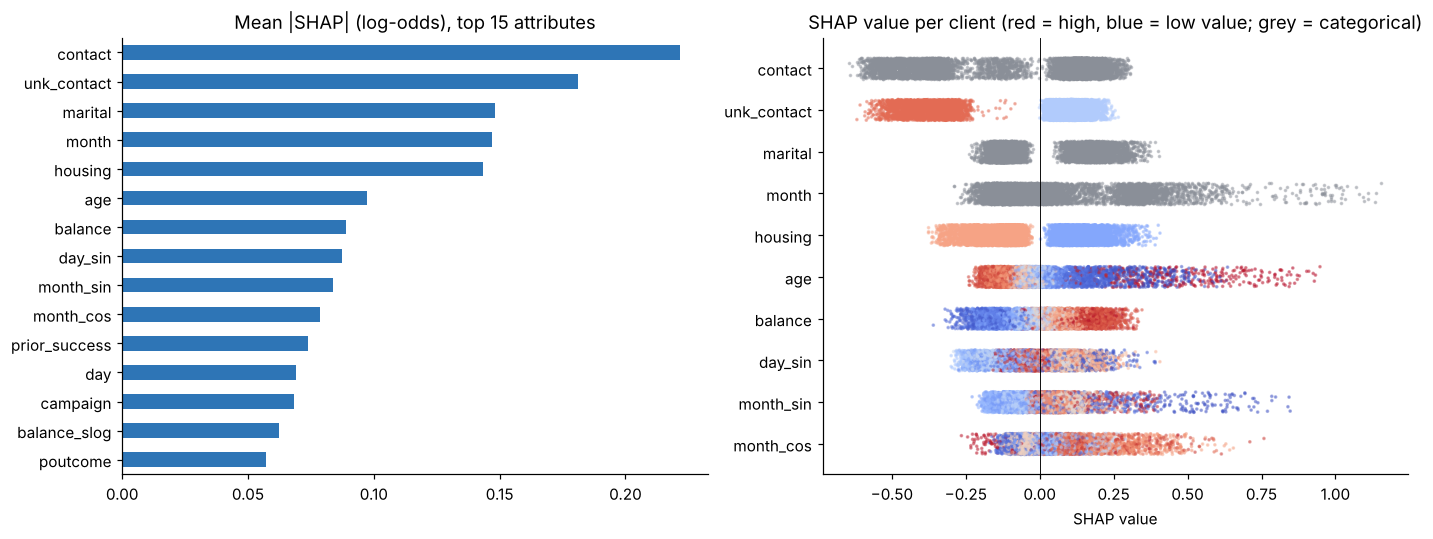

In [26]:
shap_model = Pipeline([("pre", make_pre(False)), ("clf", lgbm(**BEST_LGB))]).fit(D_tr, y_tr)
Xte_enc = shap_model["pre"].transform(D_te)
contrib = shap_model["clf"].booster_.predict(Xte_enc, pred_contrib=True)[:, :-1]
# Parent attribute by position: numeric columns map to themselves, one-hot columns to their nominal attribute.
shap_cats = shap_model["pre"].named_transformers_["cat"].categories_
shap_grp = NUMERIC + [g for g, cats in zip(NOMINAL, shap_cats) for _ in cats]
assert len(shap_grp) == contrib.shape[1]
S = pd.DataFrame(contrib).T.groupby(np.array(shap_grp)).sum().T
imp = S.abs().mean().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
imp.head(15).iloc[::-1].plot.barh(ax=ax[0], color="#2e75b6"); ax[0].set(title="Mean |SHAP| (log-odds), top 15 attributes")
for i, f in enumerate(imp.head(10).index[::-1]):
    v = S[f].values; jitter = np.random.RandomState(SEED + i).uniform(-.25, .25, len(v))
    if f in NUMERIC:   # colour by the feature's value (percentile rank); fixed 0–1 scale
        ax[1].scatter(v, i + jitter, c=D_te[f].rank(pct=True).fillna(.5).values, cmap="coolwarm", vmin=0, vmax=1, s=2, alpha=.4)
    else:              # nominal attribute: no high/low ordering, so plot in grey
        ax[1].scatter(v, i + jitter, color="#8a8f98", s=2, alpha=.4)
ax[1].set_yticks(range(10)); ax[1].set_yticklabels(imp.head(10).index[::-1]); ax[1].axvline(0, c="k", lw=.6)
ax[1].set(title="SHAP value per client (red = high, blue = low value; grey = categorical)", xlabel="SHAP value")
save("shap_summary.png")
RESULTS["shap_top15"] = imp.head(15).round(5).to_dict()

# 7. Summary

In [27]:
s = test.loc["Final model (ours)"]; b = test.loc["Neural Network / MLP (2014)"]
summary = pd.DataFrame({
    "2014-style neural network": [b.roc_auc, b.pr_auc, b["recall@0.5"], b["f1@0.5"], b.top10_capture, gains50[base]],
    "Our final model (" + FINAL_NAME + ")": [s.roc_auc, s.pr_auc, s["recall@thr"], s["f1@thr"], s.top10_capture, gains50[best]]},
    index=["ROC-AUC", "PR-AUC", "Recall (NN at 0.5, ours at tuned threshold)", "F1 (NN at 0.5, ours at tuned threshold)", "Buyers in top 10% of calls", "Buyers in top 50% of calls"])
display(summary.round(4))
RESULTS["headline"] = summary.round(5).to_dict()
json.dump(RESULTS, open(RES + "results.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
test.round(5).to_csv(RES + "test_results.csv"); cmp.round(5).to_csv(RES + "cv_model_comparison.csv")
print("saved results/results.json")

,2014-style neural network,Our final model (Blend LightGBM+CatBoost)
ROC-AUC,0.7940,0.8108
PR-AUC,0.4320,0.4743
"Recall (NN at 0.5, ours at tuned threshold)",0.1928,0.5586
"F1 (NN at 0.5, ours at tuned threshold)",0.2998,0.5006
Buyers in top 10% of calls,0.4310,0.4565
Buyers in top 50% of calls,0.8318,0.8393


saved results/results.json
